# Sentiment Classification Model Training and Evaluation

## Objective

This notebook trains and evaluates machine learning models for sentiment classification using energy app review text.

The models trained in this notebook are:

1. CountVectorizer + Multinomial Naive Bayes
2. TF-IDF + Logistic Regression

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

The goal is to compare a simple probabilistic text classifier with a stronger linear classification model.

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

REPORTS_DIR = Path("../reports")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [56]:
data_path = "../data/processed/energy_app_reviews_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df[["app_name", "rating", "sentiment", "clean_review_text"]].head()

Dataset shape: (3070, 14)


,app_name,rating,sentiment,clean_review_text
0,Octopus Electroverse,4,Positive,good app map always default charing cross would better choice default home last used
1,Octopus Electroverse,5,Positive,fantastic
2,Octopus Electroverse,5,Positive,honest say decided go electric car nervous regarding charging network support however installing app game changer re...
3,Octopus Electroverse,5,Positive,app seems fine support excellent problem account able log could reply email answer human sorted thanks ryan l
4,Octopus Electroverse,5,Positive,easy fast use also cover wide range charge point


In [57]:
X = df["clean_review_text"]
y = df["sentiment"]

print("Number of reviews:", len(X))

print("\nSentiment distribution:")
print(y.value_counts())

Number of reviews: 3070

Sentiment distribution:
sentiment
Negative    1439
Positive    1411
Neutral      220
Name: count, dtype: int64


In [58]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 2456
Testing samples: 614

Training sentiment distribution:
sentiment
Negative    1151
Positive    1129
Neutral      176
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Negative    288
Positive    282
Neutral      44
Name: count, dtype: int64


In [59]:
custom_stopwords = [
    "app",
    "apps",
    "nu",
    "sa",
    "la",
    "si",
    "de"
]

In [60]:
count_nb_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            CountVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            MultinomialNB()
        )
    ]
)

tfidf_logreg_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Model pipelines created successfully.")

Model pipelines created successfully.


In [61]:
print("Training CountVectorizer + Naive Bayes model...")

count_nb_pipeline.fit(X_train, y_train)

print("Training completed.")

Training CountVectorizer + Naive Bayes model...
Training completed.


In [62]:
print("Training TF-IDF + Logistic Regression model...")

tfidf_logreg_pipeline.fit(X_train, y_train)

print("Training completed.")

Training TF-IDF + Logistic Regression model...
Training completed.


In [63]:
y_pred_count_nb = count_nb_pipeline.predict(X_test)
y_pred_tfidf_logreg = tfidf_logreg_pipeline.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [64]:
def evaluate_model(model_name, y_true, y_pred):
    """
    Evaluate a classification model and return key metrics.
    """

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "model_name": model_name,
        "accuracy": accuracy,
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted
    }

In [65]:
model_results = []

model_results.append(
    evaluate_model(
        "CountVectorizer + Naive Bayes",
        y_test,
        y_pred_count_nb
    )
)

model_results.append(
    evaluate_model(
        "TF-IDF + Logistic Regression",
        y_test,
        y_pred_tfidf_logreg
    )
)

results_df = pd.DataFrame(model_results)

results_df

,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,CountVectorizer + Naive Bayes,0.806189,0.654281,0.597959,0.595963,0.785474
1,TF-IDF + Logistic Regression,0.765472,0.614494,0.620124,0.615214,0.773560


In [66]:
results_df.to_csv("../reports/sentiment_model_results.csv", index=False)

print("Model results saved to ../reports/sentiment_model_results.csv")

Model results saved to ../reports/sentiment_model_results.csv


In [67]:
print("Classification Report: CountVectorizer + Naive Bayes")
print(classification_report(y_test, y_pred_count_nb, zero_division=0))

Classification Report: CountVectorizer + Naive Bayes
              precision    recall  f1-score   support

    Negative       0.79      0.89      0.84       288
     Neutral       0.33      0.07      0.11        44
    Positive       0.84      0.83      0.83       282

    accuracy                           0.81       614
   macro avg       0.65      0.60      0.60       614
weighted avg       0.78      0.81      0.79       614



In [68]:
report_count_nb = classification_report(
    y_test,
    y_pred_count_nb,
    output_dict=True,
    zero_division=0
)

report_count_nb_df = pd.DataFrame(report_count_nb).transpose()

report_count_nb_df.to_csv(
    "../reports/classification_report_count_nb_sentiment.csv"
)

report_count_nb_df

,precision,recall,f1-score,support
Negative,0.793210,0.892361,0.839869,288.000000
Neutral,0.333333,0.068182,0.113208,44.000000
Positive,0.836299,0.833333,0.834813,282.000000
accuracy,0.806189,0.806189,0.806189,0.806189
macro avg,0.654281,0.597959,0.595963,614.000000
weighted avg,0.780045,0.806189,0.785474,614.000000


In [69]:
print("Classification Report: TF-IDF + Logistic Regression")
print(classification_report(y_test, y_pred_tfidf_logreg, zero_division=0))

Classification Report: TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    Negative       0.80      0.81      0.81       288
     Neutral       0.18      0.25      0.21        44
    Positive       0.86      0.80      0.83       282

    accuracy                           0.77       614
   macro avg       0.61      0.62      0.62       614
weighted avg       0.78      0.77      0.77       614



In [70]:
report_tfidf_logreg = classification_report(
    y_test,
    y_pred_tfidf_logreg,
    output_dict=True,
    zero_division=0
)

report_tfidf_logreg_df = pd.DataFrame(report_tfidf_logreg).transpose()

report_tfidf_logreg_df.to_csv(
    "../reports/classification_report_tfidf_logreg_sentiment.csv"
)

report_tfidf_logreg_df

,precision,recall,f1-score,support
Negative,0.801370,0.812500,0.806897,288.000000
Neutral,0.183333,0.250000,0.211538,44.000000
Positive,0.858779,0.797872,0.827206,282.000000
accuracy,0.765472,0.765472,0.765472,0.765472
macro avg,0.614494,0.620124,0.615214,614.000000
weighted avg,0.783447,0.765472,0.773560,614.000000


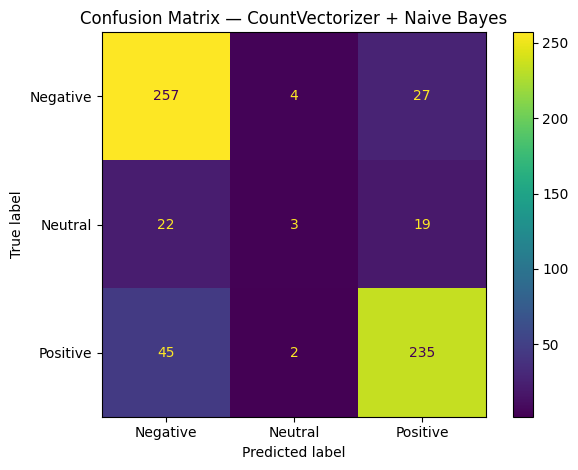

In [71]:
labels = ["Negative", "Neutral", "Positive"]

cm_count_nb = confusion_matrix(
    y_test,
    y_pred_count_nb,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_count_nb,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — CountVectorizer + Naive Bayes")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_count_nb_sentiment.png",
    dpi=300
)

plt.show()

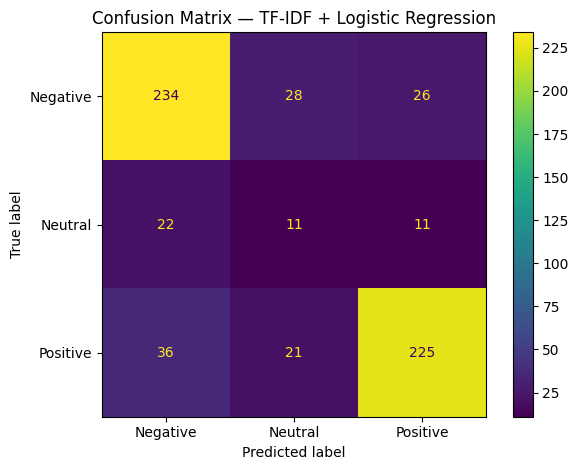

In [72]:
cm_tfidf_logreg = confusion_matrix(
    y_test,
    y_pred_tfidf_logreg,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tfidf_logreg,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — TF-IDF + Logistic Regression")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_tfidf_logreg_sentiment.png",
    dpi=300
)

plt.show()

In [73]:
joblib.dump(
    count_nb_pipeline,
    "../models/count_nb_sentiment_model.pkl"
)

joblib.dump(
    tfidf_logreg_pipeline,
    "../models/tfidf_logreg_sentiment_model.pkl"
)

print("Models saved successfully.")

Models saved successfully.


In [74]:
example_reviews = [
    "The charging station worked perfectly and the app was very easy to use.",
    "I cannot log in and the payment keeps failing every time.",
    "The service is okay but the app needs some improvements."
]

example_predictions = pd.DataFrame({
    "review": example_reviews,
    "count_nb_prediction": count_nb_pipeline.predict(example_reviews),
    "tfidf_logreg_prediction": tfidf_logreg_pipeline.predict(example_reviews)
})

example_predictions

,review,count_nb_prediction,tfidf_logreg_prediction
0,The charging station worked perfectly and the app was very easy to use.,Positive,Positive
1,I cannot log in and the payment keeps failing every time.,Negative,Negative
2,The service is okay but the app needs some improvements.,Positive,Neutral


## Model Training Observations

Two sentiment classification models were trained and compared.

The CountVectorizer + Naive Bayes model provides a fast and interpretable baseline. It uses raw word and phrase counts to classify review sentiment.

The TF-IDF + Logistic Regression model uses weighted text features and a linear classifier. TF-IDF reduces the influence of very common terms and often improves classification performance for text data.

Because the neutral class is smaller than the positive and negative classes, macro F1-score is important in addition to accuracy. Accuracy gives the overall correctness, while macro F1 gives a better view of how well the model performs across all sentiment classes.

The confusion matrices help identify which classes are most often confused by the models.

# Model Tuning and Final Sentiment Model Selection

The baseline models showed strong performance for positive and negative reviews, but weaker performance for the neutral class.

This section compares additional model configurations to identify a better final sentiment classifier.

The goal is not only to maximize accuracy, but also to improve macro F1-score because the neutral class is underrepresented.

In [75]:
from sklearn.model_selection import GridSearchCV

tuned_pipelines = {
    "CountVectorizer + Naive Bayes": Pipeline(
        steps=[
            (
                "vectorizer",
                CountVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            ("model", MultinomialNB())
        ]
    ),

    "TF-IDF + Naive Bayes": Pipeline(
        steps=[
            (
                "vectorizer",
                TfidfVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            ("model", MultinomialNB())
        ]
    ),

    "CountVectorizer + Logistic Regression": Pipeline(
        steps=[
            (
                "vectorizer",
                CountVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    ),

    "TF-IDF + Logistic Regression": Pipeline(
        steps=[
            (
                "vectorizer",
                TfidfVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    )
}

print("Tuned pipelines created.")

Tuned pipelines created.


In [76]:
param_grids = {
    "CountVectorizer + Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1.0, 2.0]
    },

    "TF-IDF + Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1.0, 2.0]
    },

    "CountVectorizer + Logistic Regression": {
        "model__C": [0.5, 1.0, 2.0],
        "model__class_weight": [None, "balanced"]
    },

    "TF-IDF + Logistic Regression": {
        "model__C": [0.5, 1.0, 2.0],
        "model__class_weight": [None, "balanced"]
    }
}

print("Parameter grids created.")

Parameter grids created.


In [77]:
tuning_results = []
best_models = {}

for model_name, pipeline in tuned_pipelines.items():
    print("=" * 80)
    print(f"Tuning model: {model_name}")
    print("=" * 80)

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="f1_macro",
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    best_models[model_name] = best_model

    y_pred = best_model.predict(X_test)

    evaluation = evaluate_model(
        model_name=model_name,
        y_true=y_test,
        y_pred=y_pred
    )

    evaluation["best_params"] = grid_search.best_params_
    evaluation["best_cv_macro_f1"] = grid_search.best_score_

    tuning_results.append(evaluation)

    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best CV macro F1: {grid_search.best_score_:.4f}")
    print()

Tuning model: CountVectorizer + Naive Bayes
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__alpha': 0.5}
Best CV macro F1: 0.6041

Tuning model: TF-IDF + Naive Bayes
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__alpha': 0.1}
Best CV macro F1: 0.5700

Tuning model: CountVectorizer + Logistic Regression
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__C': 0.5, 'model__class_weight': 'balanced'}
Best CV macro F1: 0.6211

Tuning model: TF-IDF + Logistic Regression
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__C': 1.0, 'model__class_weight': 'balanced'}
Best CV macro F1: 0.6382



In [78]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="macro_f1",
    ascending=False
)

tuning_results_df

,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,best_params,best_cv_macro_f1
0,CountVectorizer + Naive Bayes,0.801303,0.656054,0.613692,0.620304,0.787794,{'model__alpha': 0.5},0.604128
2,CountVectorizer + Logistic Regression,0.762215,0.616160,0.624523,0.618826,0.767304,"{'model__C': 0.5, 'model__class_weight': 'balanced'}",0.621073
3,TF-IDF + Logistic Regression,0.765472,0.614494,0.620124,0.615214,0.773560,"{'model__C': 1.0, 'model__class_weight': 'balanced'}",0.638165
1,TF-IDF + Naive Bayes,0.804560,0.761988,0.590260,0.583776,0.779520,{'model__alpha': 0.1},0.570009


In [79]:
tuning_results_df.to_csv(
    "../reports/sentiment_model_tuning_results.csv",
    index=False
)

print("Tuning results saved to ../reports/sentiment_model_tuning_results.csv")

Tuning results saved to ../reports/sentiment_model_tuning_results.csv


In [80]:
best_model_name = tuning_results_df.iloc[0]["model_name"]
final_sentiment_model = best_models[best_model_name]

print("Best tuned sentiment model:")
print(best_model_name)

print("\nBest model metrics:")
display(tuning_results_df.head(1))

Best tuned sentiment model:
CountVectorizer + Naive Bayes

Best model metrics:


,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,best_params,best_cv_macro_f1
0,CountVectorizer + Naive Bayes,0.801303,0.656054,0.613692,0.620304,0.787794,{'model__alpha': 0.5},0.604128


In [81]:
y_pred_final_sentiment = final_sentiment_model.predict(X_test)

print(f"Classification Report: {best_model_name}")
print(classification_report(y_test, y_pred_final_sentiment, zero_division=0))

Classification Report: CountVectorizer + Naive Bayes
              precision    recall  f1-score   support

    Negative       0.79      0.88      0.83       288
     Neutral       0.33      0.14      0.19        44
    Positive       0.84      0.83      0.84       282

    accuracy                           0.80       614
   macro avg       0.66      0.61      0.62       614
weighted avg       0.78      0.80      0.79       614



In [82]:
final_report = classification_report(
    y_test,
    y_pred_final_sentiment,
    output_dict=True,
    zero_division=0
)

final_report_df = pd.DataFrame(final_report).transpose()

final_report_df.to_csv(
    "../reports/classification_report_final_sentiment_model.csv"
)

final_report_df

,precision,recall,f1-score,support
Negative,0.790625,0.878472,0.832237,288.000000
Neutral,0.333333,0.136364,0.193548,44.000000
Positive,0.844203,0.826241,0.835125,282.000000
accuracy,0.801303,0.801303,0.801303,0.801303
macro avg,0.656054,0.613692,0.620304,614.000000
weighted avg,0.782462,0.801303,0.787794,614.000000


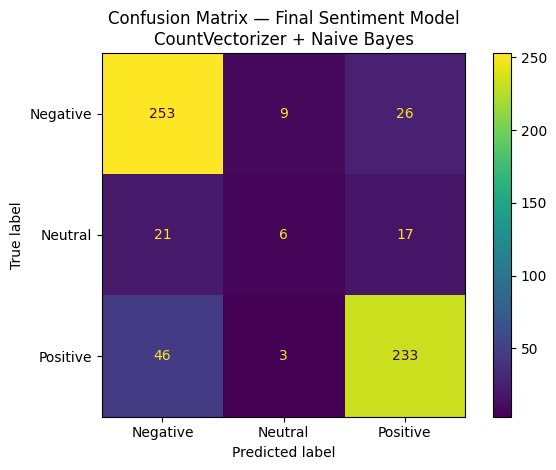

In [83]:
cm_final = confusion_matrix(
    y_test,
    y_pred_final_sentiment,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix — Final Sentiment Model\n{best_model_name}")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_final_sentiment_model.png",
    dpi=300
)

plt.show()

In [84]:
joblib.dump(
    final_sentiment_model,
    "../models/final_sentiment_model.pkl"
)

print("Final sentiment model saved locally.")

Final sentiment model saved locally.


# Final Baseline vs Tuned Model Comparison

The project first trained baseline sentiment classification models using standard/simple model settings.

After reviewing the baseline results, model tuning was performed using GridSearchCV. The goal of tuning was not only to improve accuracy, but also to improve macro F1-score because the neutral class is underrepresented.

This final comparison summarizes:

1. The best baseline model by accuracy
2. The best baseline model by macro F1-score
3. The final selected tuned model

Macro F1-score is important because it treats Negative, Neutral, and Positive classes equally.

In [85]:
# Simple final comparison: best baseline accuracy vs final tuned model

baseline_best_accuracy = results_df.loc[
    results_df["accuracy"].idxmax()
].copy()

tuned_best_macro_f1 = tuning_results_df.loc[
    tuning_results_df["macro_f1"].idxmax()
].copy()

final_model_comparison_simple = pd.DataFrame([
    {
        "stage": "Baseline",
        "model_name": baseline_best_accuracy["model_name"],
        "selection_criterion": "Best baseline accuracy",
        "accuracy": baseline_best_accuracy["accuracy"],
        "macro_f1": baseline_best_accuracy["macro_f1"],
        "weighted_f1": baseline_best_accuracy["weighted_f1"],
        "best_params": "Default / baseline settings"
    },
    {
        "stage": "Tuned",
        "model_name": tuned_best_macro_f1["model_name"],
        "selection_criterion": "Best tuned macro F1",
        "accuracy": tuned_best_macro_f1["accuracy"],
        "macro_f1": tuned_best_macro_f1["macro_f1"],
        "weighted_f1": tuned_best_macro_f1["weighted_f1"],
        "best_params": tuned_best_macro_f1["best_params"]
    }
])

final_model_comparison_simple[["accuracy", "macro_f1", "weighted_f1"]] = (
    final_model_comparison_simple[["accuracy", "macro_f1", "weighted_f1"]].round(4)
)

final_model_comparison_simple

,stage,model_name,selection_criterion,accuracy,macro_f1,weighted_f1,best_params
0,Baseline,CountVectorizer + Naive Bayes,Best baseline accuracy,0.8062,0.5960,0.7855,Default / baseline settings
1,Tuned,CountVectorizer + Naive Bayes,Best tuned macro F1,0.8013,0.6203,0.7878,{'model__alpha': 0.5}


In [86]:
final_model_comparison.to_csv(
    "../reports/final_baseline_vs_tuned_model_comparison.csv",
    index=False
)

print("Final baseline vs tuned model comparison saved successfully.")

Final baseline vs tuned model comparison saved successfully.


## Final Model Interpretation

The baseline results show that a simple CountVectorizer + Naive Bayes model already performs well for this sentiment classification task, especially for clearly positive and clearly negative reviews.

However, accuracy alone is not enough for this dataset because the neutral class is much smaller than the positive and negative classes. Therefore, macro F1-score was used as the main selection metric during model tuning.

After tuning, the final selected model achieved a slightly better macro F1-score. The improvement is modest but meaningful because it shows better balance across sentiment classes.

The final model still performs best on positive and negative reviews. Neutral reviews remain more difficult because they are fewer in number and often contain mixed language, such as partial satisfaction combined with complaints.

This is a realistic result for a real-world review dataset.






------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# Rating Prediction Model

## Objective

In this section, the task is to predict the original 1 to 5 star rating from review text.

Unlike sentiment classification, rating prediction is a more detailed multi-class classification problem.

The target classes are:

- 1 star
- 2 stars
- 3 stars
- 4 stars
- 5 stars

This task is harder because the dataset is imbalanced. Most reviews are either 1-star or 5-star, while 2-star, 3-star, and 4-star reviews are much fewer.

The models trained are:

1. CountVectorizer + Naive Bayes
2. TF-IDF + Logistic Regression

The models are evaluated using:

- Accuracy
- Macro F1-score
- Weighted F1-score
- Mean Absolute Error
- Confusion matrix



In [87]:
# Prepare input text and rating target

X_rating = df["clean_review_text"]
y_rating = df["rating"]

print("Number of reviews:", len(X_rating))

print("\nRating distribution:")
print(y_rating.value_counts().sort_index())

Number of reviews: 3070

Rating distribution:
rating
1    1229
2     210
3     220
4     234
5    1177
Name: count, dtype: int64


In [88]:
X_train_rating, X_test_rating, y_train_rating, y_test_rating = train_test_split(
    X_rating,
    y_rating,
    test_size=0.2,
    random_state=42,
    stratify=y_rating
)

print("Training samples:", X_train_rating.shape[0])
print("Testing samples:", X_test_rating.shape[0])

print("\nTraining rating distribution:")
print(y_train_rating.value_counts().sort_index())

print("\nTesting rating distribution:")
print(y_test_rating.value_counts().sort_index())

Training samples: 2456
Testing samples: 614

Training rating distribution:
rating
1    983
2    168
3    176
4    187
5    942
Name: count, dtype: int64

Testing rating distribution:
rating
1    246
2     42
3     44
4     47
5    235
Name: count, dtype: int64


In [89]:
count_nb_rating_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            CountVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            MultinomialNB()
        )
    ]
)

tfidf_logreg_rating_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Rating prediction pipelines created successfully.")

Rating prediction pipelines created successfully.


In [90]:
print("Training CountVectorizer + Naive Bayes rating model...")
count_nb_rating_pipeline.fit(X_train_rating, y_train_rating)
print("Training completed.")

print("\nTraining TF-IDF + Logistic Regression rating model...")
tfidf_logreg_rating_pipeline.fit(X_train_rating, y_train_rating)
print("Training completed.")

Training CountVectorizer + Naive Bayes rating model...
Training completed.

Training TF-IDF + Logistic Regression rating model...
Training completed.


In [91]:
y_pred_count_nb_rating = count_nb_rating_pipeline.predict(X_test_rating)
y_pred_tfidf_logreg_rating = tfidf_logreg_rating_pipeline.predict(X_test_rating)

print("Rating predictions completed.")

Rating predictions completed.


In [92]:
from sklearn.metrics import mean_absolute_error


def evaluate_rating_model(model_name, y_true, y_pred):
    """
    Evaluate a rating prediction model.

    Ratings are treated as multi-class labels from 1 to 5.
    Mean Absolute Error is also included because star ratings are ordered.
    """

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    mae = mean_absolute_error(y_true, y_pred)

    return {
        "model_name": model_name,
        "accuracy": accuracy,
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted,
        "mean_absolute_error": mae
    }

In [93]:
rating_model_results = []

rating_model_results.append(
    evaluate_rating_model(
        "CountVectorizer + Naive Bayes",
        y_test_rating,
        y_pred_count_nb_rating
    )
)

rating_model_results.append(
    evaluate_rating_model(
        "TF-IDF + Logistic Regression",
        y_test_rating,
        y_pred_tfidf_logreg_rating
    )
)

rating_results_df = pd.DataFrame(rating_model_results)

rating_results_df = rating_results_df.sort_values(
    by="macro_f1",
    ascending=False
)

rating_results_df

,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_absolute_error
1,TF-IDF + Logistic Regression,0.597720,0.403802,0.403563,0.400276,0.617158,0.732899
0,CountVectorizer + Naive Bayes,0.684039,0.446504,0.396488,0.395767,0.639913,0.739414


In [94]:
rating_results_df.to_csv(
    "../reports/rating_model_results.csv",
    index=False
)

print("Rating model results saved to ../reports/rating_model_results.csv")

Rating model results saved to ../reports/rating_model_results.csv


In [95]:
print("Classification Report: CountVectorizer + Naive Bayes Rating Prediction")
print(classification_report(y_test_rating, y_pred_count_nb_rating, zero_division=0))

Classification Report: CountVectorizer + Naive Bayes Rating Prediction
              precision    recall  f1-score   support

           1       0.69      0.88      0.78       246
           2       0.13      0.05      0.07        42
           3       0.37      0.16      0.22        44
           4       0.29      0.09      0.13        47
           5       0.75      0.81      0.78       235

    accuracy                           0.68       614
   macro avg       0.45      0.40      0.40       614
weighted avg       0.62      0.68      0.64       614



In [96]:
report_count_nb_rating = classification_report(
    y_test_rating,
    y_pred_count_nb_rating,
    output_dict=True,
    zero_division=0
)

report_count_nb_rating_df = pd.DataFrame(report_count_nb_rating).transpose()

report_count_nb_rating_df.to_csv(
    "../reports/classification_report_count_nb_rating.csv"
)

report_count_nb_rating_df

,precision,recall,f1-score,support
1,0.691083,0.882114,0.775000,246.000000
2,0.133333,0.047619,0.070175,42.000000
3,0.368421,0.159091,0.222222,44.000000
4,0.285714,0.085106,0.131148,47.000000
5,0.753968,0.808511,0.780287,235.000000
accuracy,0.684039,0.684039,0.684039,0.684039
macro avg,0.446504,0.396488,0.395767,614.000000
weighted avg,0.622847,0.684039,0.639913,614.000000


In [97]:
print("Classification Report: TF-IDF + Logistic Regression Rating Prediction")
print(classification_report(y_test_rating, y_pred_tfidf_logreg_rating, zero_division=0))

Classification Report: TF-IDF + Logistic Regression Rating Prediction
              precision    recall  f1-score   support

           1       0.73      0.73      0.73       246
           2       0.13      0.17      0.15        42
           3       0.16      0.20      0.18        44
           4       0.17      0.23      0.20        47
           5       0.82      0.68      0.75       235

    accuracy                           0.60       614
   macro avg       0.40      0.40      0.40       614
weighted avg       0.64      0.60      0.62       614



In [98]:
report_tfidf_logreg_rating = classification_report(
    y_test_rating,
    y_pred_tfidf_logreg_rating,
    output_dict=True,
    zero_division=0
)

report_tfidf_logreg_rating_df = pd.DataFrame(report_tfidf_logreg_rating).transpose()

report_tfidf_logreg_rating_df.to_csv(
    "../reports/classification_report_tfidf_logreg_rating.csv"
)

report_tfidf_logreg_rating_df

,precision,recall,f1-score,support
1,0.734694,0.731707,0.733198,246.00000
2,0.129630,0.166667,0.145833,42.00000
3,0.160714,0.204545,0.180000,44.00000
4,0.169231,0.234043,0.196429,47.00000
5,0.824742,0.680851,0.745921,235.00000
accuracy,0.597720,0.597720,0.597720,0.59772
macro avg,0.403802,0.403563,0.400276,614.00000
weighted avg,0.643353,0.597720,0.617158,614.00000


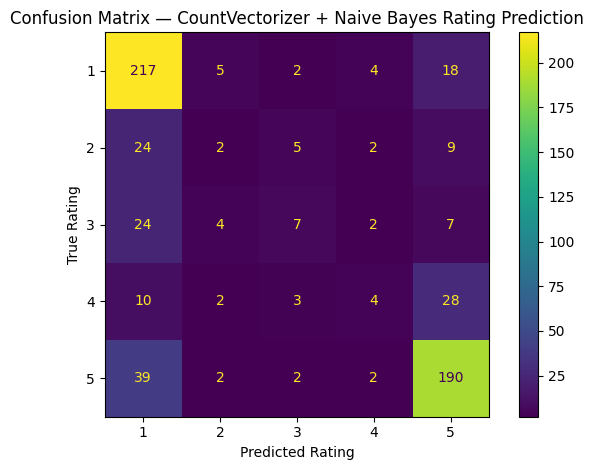

In [99]:
rating_labels = [1, 2, 3, 4, 5]

cm_count_nb_rating = confusion_matrix(
    y_test_rating,
    y_pred_count_nb_rating,
    labels=rating_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_count_nb_rating,
    display_labels=rating_labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — CountVectorizer + Naive Bayes Rating Prediction")
plt.xlabel("Predicted Rating")
plt.ylabel("True Rating")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_count_nb_rating.png",
    dpi=300
)

plt.show()

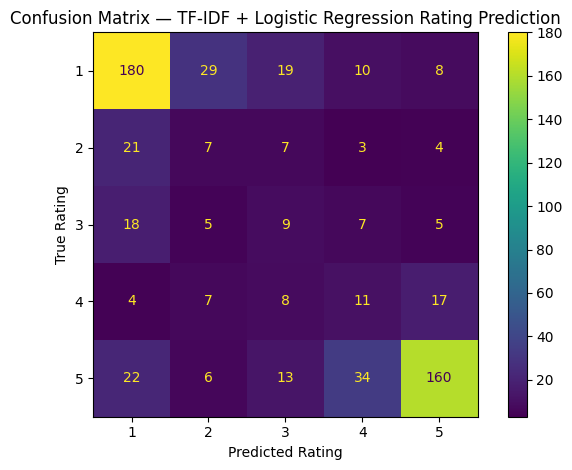

In [100]:
cm_tfidf_logreg_rating = confusion_matrix(
    y_test_rating,
    y_pred_tfidf_logreg_rating,
    labels=rating_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tfidf_logreg_rating,
    display_labels=rating_labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — TF-IDF + Logistic Regression Rating Prediction")
plt.xlabel("Predicted Rating")
plt.ylabel("True Rating")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_tfidf_logreg_rating.png",
    dpi=300
)

plt.show()

In [101]:
joblib.dump(
    count_nb_rating_pipeline,
    "../models/count_nb_rating_model.pkl"
)

joblib.dump(
    tfidf_logreg_rating_pipeline,
    "../models/tfidf_logreg_rating_model.pkl"
)

print("Rating prediction models saved locally.")


Rating prediction models saved locally.


In [102]:
example_rating_reviews = [
    "The charging station worked perfectly and the app was very easy to use.",
    "I cannot log in and the payment keeps failing every time.",
    "The service is okay but the app needs some improvements.",
    "Terrible app. Nothing works and customer support never responds.",
    "Excellent experience, very useful and reliable charging service."
]

example_rating_predictions = pd.DataFrame({
    "review": example_rating_reviews,
    "count_nb_predicted_rating": count_nb_rating_pipeline.predict(example_rating_reviews),
    "tfidf_logreg_predicted_rating": tfidf_logreg_rating_pipeline.predict(example_rating_reviews)
})

example_rating_predictions

,review,count_nb_predicted_rating,tfidf_logreg_predicted_rating
0,The charging station worked perfectly and the app was very easy to use.,5,5
1,I cannot log in and the payment keeps failing every time.,1,1
2,The service is okay but the app needs some improvements.,5,3
3,Terrible app. Nothing works and customer support never responds.,1,1
4,"Excellent experience, very useful and reliable charging service.",5,5


## Rating Prediction Observations

Rating prediction is more difficult than sentiment classification because the model must distinguish between five rating levels instead of three sentiment classes.

The dataset is highly polarized, with most reviews belonging to 1-star and 5-star ratings. Ratings 2, 3, and 4 have fewer examples, so the models may struggle to classify these middle ratings correctly.

Accuracy gives the percentage of exactly correct rating predictions. However, Mean Absolute Error is also useful because ratings are ordered. Predicting 4 instead of 5 is a smaller mistake than predicting 1 instead of 5.

The confusion matrix helps show whether the model mainly confuses neighboring ratings or makes large rating errors.

----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------



# Rating Prediction Model Tuning

The baseline rating prediction models showed that exact 1-to-5 star rating prediction is more difficult than sentiment classification.

The main challenge is class imbalance. Most reviews are either 1-star or 5-star, while 2-star, 3-star, and 4-star reviews are much fewer.

In this section, additional model configurations are tested using GridSearchCV.

The tuning goal is to improve macro F1-score because macro F1 gives equal importance to all five rating classes.

In [104]:
from sklearn.model_selection import GridSearchCV

rating_tuned_pipelines = {
    "CountVectorizer + Naive Bayes": Pipeline(
        steps=[
            (
                "vectorizer",
                CountVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            ("model", MultinomialNB())
        ]
    ),

    "TF-IDF + Naive Bayes": Pipeline(
        steps=[
            (
                "vectorizer",
                TfidfVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            ("model", MultinomialNB())
        ]
    ),

    "CountVectorizer + Logistic Regression": Pipeline(
        steps=[
            (
                "vectorizer",
                CountVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ]
    ),

    "TF-IDF + Logistic Regression": Pipeline(
        steps=[
            (
                "vectorizer",
                TfidfVectorizer(
                    max_features=5000,
                    ngram_range=(1, 2),
                    min_df=3,
                    max_df=0.90,
                    stop_words=custom_stopwords,
                    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
                )
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ]
    )
}

print("Rating tuning pipelines created successfully.")

Rating tuning pipelines created successfully.


In [105]:
rating_param_grids = {
    "CountVectorizer + Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1.0, 2.0]
    },

    "TF-IDF + Naive Bayes": {
        "model__alpha": [0.1, 0.5, 1.0, 2.0]
    },

    "CountVectorizer + Logistic Regression": {
        "model__C": [0.5, 1.0, 2.0],
        "model__class_weight": [None, "balanced"]
    },

    "TF-IDF + Logistic Regression": {
        "model__C": [0.5, 1.0, 2.0],
        "model__class_weight": [None, "balanced"]
    }
}

print("Rating parameter grids created successfully.")

Rating parameter grids created successfully.


In [106]:
rating_tuning_results = []
best_rating_models = {}

for model_name, pipeline in rating_tuned_pipelines.items():
    print("=" * 80)
    print(f"Tuning rating model: {model_name}")
    print("=" * 80)

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=rating_param_grids[model_name],
        scoring="f1_macro",
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train_rating, y_train_rating)

    best_model = grid_search.best_estimator_
    best_rating_models[model_name] = best_model

    y_pred_rating_tuned = best_model.predict(X_test_rating)

    evaluation = evaluate_rating_model(
        model_name=model_name,
        y_true=y_test_rating,
        y_pred=y_pred_rating_tuned
    )

    evaluation["best_params"] = grid_search.best_params_
    evaluation["best_cv_macro_f1"] = grid_search.best_score_

    rating_tuning_results.append(evaluation)

    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best CV macro F1: {grid_search.best_score_:.4f}")
    print()

Tuning rating model: CountVectorizer + Naive Bayes
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__alpha': 0.5}
Best CV macro F1: 0.4033

Tuning rating model: TF-IDF + Naive Bayes
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters: {'model__alpha': 0.1}
Best CV macro F1: 0.3718

Tuning rating model: CountVectorizer + Logistic Regression
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__C': 1.0, 'model__class_weight': 'balanced'}
Best CV macro F1: 0.4191

Tuning rating model: TF-IDF + Logistic Regression
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'model__C': 0.5, 'model__class_weight': 'balanced'}
Best CV macro F1: 0.4276



In [107]:
rating_tuning_results_df = pd.DataFrame(rating_tuning_results)

rating_tuning_results_df = rating_tuning_results_df.sort_values(
    by=["macro_f1", "mean_absolute_error"],
    ascending=[False, True]
)

rating_tuning_results_df

,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_absolute_error,best_params,best_cv_macro_f1
2,CountVectorizer + Logistic Regression,0.646580,0.431975,0.429273,0.430230,0.642627,0.729642,"{'model__C': 1.0, 'model__class_weight': 'balanced'}",0.419134
3,TF-IDF + Logistic Regression,0.591205,0.408093,0.406955,0.401638,0.609898,0.760586,"{'model__C': 0.5, 'model__class_weight': 'balanced'}",0.427579
0,CountVectorizer + Naive Bayes,0.666124,0.416404,0.394125,0.394506,0.634351,0.760586,{'model__alpha': 0.5},0.403296
1,TF-IDF + Naive Bayes,0.688925,0.444472,0.372581,0.355663,0.624594,0.744300,{'model__alpha': 0.1},0.371840


In [108]:
rating_tuning_results_df.to_csv(
    "../reports/rating_model_tuning_results.csv",
    index=False
)

print("Rating model tuning results saved successfully.")

Rating model tuning results saved successfully.


In [109]:
best_rating_model_name = rating_tuning_results_df.iloc[0]["model_name"]
final_rating_model = best_rating_models[best_rating_model_name]

print("Best tuned rating model:")
print(best_rating_model_name)

print("\nBest tuned rating model metrics:")
display(rating_tuning_results_df.head(1))

Best tuned rating model:
CountVectorizer + Logistic Regression

Best tuned rating model metrics:


,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mean_absolute_error,best_params,best_cv_macro_f1
2,CountVectorizer + Logistic Regression,0.64658,0.431975,0.429273,0.43023,0.642627,0.729642,"{'model__C': 1.0, 'model__class_weight': 'balanced'}",0.419134


In [110]:
y_pred_final_rating = final_rating_model.predict(X_test_rating)

print(f"Classification Report: Final Tuned Rating Model - {best_rating_model_name}")
print(classification_report(y_test_rating, y_pred_final_rating, zero_division=0))

Classification Report: Final Tuned Rating Model - CountVectorizer + Logistic Regression
              precision    recall  f1-score   support

           1       0.75      0.74      0.74       246
           2       0.22      0.19      0.21        42
           3       0.19      0.18      0.19        44
           4       0.23      0.23      0.23        47
           5       0.76      0.80      0.78       235

    accuracy                           0.65       614
   macro avg       0.43      0.43      0.43       614
weighted avg       0.64      0.65      0.64       614



In [111]:
final_rating_report = classification_report(
    y_test_rating,
    y_pred_final_rating,
    output_dict=True,
    zero_division=0
)

final_rating_report_df = pd.DataFrame(final_rating_report).transpose()

final_rating_report_df.to_csv(
    "../reports/classification_report_final_rating_model.csv"
)

final_rating_report_df

,precision,recall,f1-score,support
1,0.751037,0.735772,0.743326,246.00000
2,0.222222,0.190476,0.205128,42.00000
3,0.190476,0.181818,0.186047,44.00000
4,0.234043,0.234043,0.234043,47.00000
5,0.762097,0.804255,0.782609,235.00000
accuracy,0.646580,0.646580,0.646580,0.64658
macro avg,0.431975,0.429273,0.430230,614.00000
weighted avg,0.639352,0.646580,0.642627,614.00000


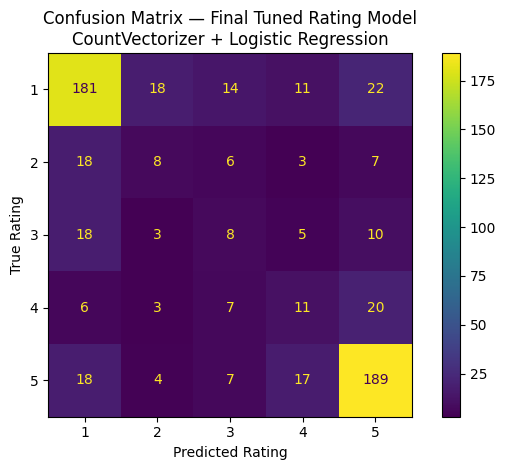

In [112]:
cm_final_rating = confusion_matrix(
    y_test_rating,
    y_pred_final_rating,
    labels=rating_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final_rating,
    display_labels=rating_labels
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix — Final Tuned Rating Model\n{best_rating_model_name}")
plt.xlabel("Predicted Rating")
plt.ylabel("True Rating")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_final_rating_model.png",
    dpi=300
)

plt.show()

In [113]:
joblib.dump(
    final_rating_model,
    "../models/final_rating_model.pkl"
)

print("Final tuned rating model saved locally.")

Final tuned rating model saved locally.


In [114]:
# Best baseline rating model by accuracy
baseline_rating_best_accuracy = rating_results_df.loc[
    rating_results_df["accuracy"].idxmax()
].copy()

# Best baseline rating model by macro F1
baseline_rating_best_macro_f1 = rating_results_df.loc[
    rating_results_df["macro_f1"].idxmax()
].copy()

# Best tuned rating model by macro F1
tuned_rating_best_macro_f1 = rating_tuning_results_df.loc[
    rating_tuning_results_df["macro_f1"].idxmax()
].copy()


final_rating_baseline_vs_tuned = pd.DataFrame([
    {
        "stage": "Baseline",
        "selection_criterion": "Best Accuracy",
        "model_name": baseline_rating_best_accuracy["model_name"],
        "accuracy": baseline_rating_best_accuracy["accuracy"],
        "macro_f1": baseline_rating_best_accuracy["macro_f1"],
        "weighted_f1": baseline_rating_best_accuracy["weighted_f1"],
        "mean_absolute_error": baseline_rating_best_accuracy["mean_absolute_error"],
        "best_params": "Default / baseline settings",
        "comment": "Best exact star-rating accuracy before tuning."
    },
    {
        "stage": "Baseline",
        "selection_criterion": "Best Macro F1",
        "model_name": baseline_rating_best_macro_f1["model_name"],
        "accuracy": baseline_rating_best_macro_f1["accuracy"],
        "macro_f1": baseline_rating_best_macro_f1["macro_f1"],
        "weighted_f1": baseline_rating_best_macro_f1["weighted_f1"],
        "mean_absolute_error": baseline_rating_best_macro_f1["mean_absolute_error"],
        "best_params": "Default / baseline settings",
        "comment": "Most balanced baseline model across the five rating classes."
    },
    {
        "stage": "Tuned",
        "selection_criterion": "Best Macro F1",
        "model_name": tuned_rating_best_macro_f1["model_name"],
        "accuracy": tuned_rating_best_macro_f1["accuracy"],
        "macro_f1": tuned_rating_best_macro_f1["macro_f1"],
        "weighted_f1": tuned_rating_best_macro_f1["weighted_f1"],
        "mean_absolute_error": tuned_rating_best_macro_f1["mean_absolute_error"],
        "best_params": tuned_rating_best_macro_f1["best_params"],
        "comment": "Selected as final tuned rating model based on macro F1."
    }
])

numeric_columns = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "mean_absolute_error"
]

final_rating_baseline_vs_tuned[numeric_columns] = (
    final_rating_baseline_vs_tuned[numeric_columns].round(4)
)

final_rating_baseline_vs_tuned

,stage,selection_criterion,model_name,accuracy,macro_f1,weighted_f1,mean_absolute_error,best_params,comment
0,Baseline,Best Accuracy,CountVectorizer + Naive Bayes,0.6840,0.3958,0.6399,0.7394,Default / baseline settings,Best exact star-rating accuracy before tuning.
1,Baseline,Best Macro F1,TF-IDF + Logistic Regression,0.5977,0.4003,0.6172,0.7329,Default / baseline settings,Most balanced baseline model across the five rating classes.
2,Tuned,Best Macro F1,CountVectorizer + Logistic Regression,0.6466,0.4302,0.6426,0.7296,"{'model__C': 1.0, 'model__class_weight': 'balanced'}",Selected as final tuned rating model based on macro F1.


In [115]:
final_rating_baseline_vs_tuned.to_csv(
    "../reports/final_rating_baseline_vs_tuned_comparison.csv",
    index=False
)

print("Final rating baseline vs tuned comparison saved successfully.")

Final rating baseline vs tuned comparison saved successfully.


## Final Rating Model Selection

The rating prediction models were tuned using macro F1-score because the five rating classes are imbalanced.

The dataset contains many 1-star and 5-star reviews, but fewer 2-star, 3-star, and 4-star reviews. Because of this, accuracy alone can be misleading. A model can achieve good accuracy by predicting the majority classes while still performing poorly on middle ratings.

Macro F1-score gives equal importance to all rating classes and is therefore useful for selecting a more balanced model.

Mean Absolute Error is also useful because ratings are ordered. Predicting 4 instead of 5 is a smaller mistake than predicting 1 instead of 5.

The final tuned rating model is selected based mainly on macro F1-score, while accuracy, weighted F1-score, and Mean Absolute Error are also considered for interpretation.

Even after tuning, exact rating prediction remains more difficult than sentiment classification because middle ratings often contain mixed language and fewer training examples.